In [1]:
import xmlrpc.client
import pickle
from PIL import Image
from pylab import *
import numpy as np
import datetime
import glob
# Режим отображения графиков внутри ноутбука
%matplotlib inline

In [2]:
print("Файлы в папке:", glob.glob('log*.csv'))

Файлы в папке: ['log.csv', 'log_20261005_192315.csv', 'log_20261005_183457.csv', 'log_20261005_183336.csv', 'log_20261005_171245.csv', 'log_20261005_143714.csv', 'log_20261005_160237.csv', 'log_20261005_173947.csv', 'log_20261005_204917.csv', 'log_20261005_192321.csv', 'log_20261005_172328.csv', 'log_20261005_160741.csv', 'log_20261005_183259.csv', 'log_20261005_145147.csv', 'log_20261005_160913.csv', 'log_20261005_152558.csv', 'log_20261005_152603.csv', 'log_20261005_204531.csv', 'log_20261005_171350.csv', 'log_20261005_161132.csv', 'log_20261005_171532.csv']


In [3]:
# Подключение к серверу
server = xmlrpc.client.ServerProxy("http://localhost:8008")
stats = xmlrpc.client.ServerProxy("http://localhost:8018", allow_none=True)


In [4]:
# Тесты
print(server.system.listMethods())
print('Ping:', server.ping())
print('Server datetime:', server.now())
print('View, type, value:', server.type(2))
print('View, type, value:', server.type(2.))
print('View, type, value:', server.type('My string'))
print('View, type, value:', server.type("My string"))
print('View, type, value:', server.type([1,2,3]))
print('View, type, value:', server.type(["one", "two", "three"]))
print('View, type, value:', server.type((1,2,"3")))
print('Sum 2 + 3 :', server.sum(2, 3))
print('Pow 2^3: ', server.pow(2, 3))

['binarize_image', 'black_list_check', 'cloud_percent', 'color_inversion', 'flip_vertical', 'now', 'ping', 'pow', 'sum', 'system.listMethods', 'system.methodHelp', 'system.methodSignature', 'type']
Ping: True
Server datetime: 20261019T14:57:36
View, type, value: ['2', "<class 'int'>", 2]
View, type, value: ['2.0', "<class 'float'>", 2.0]
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['[1, 2, 3]', "<class 'list'>", [1, 2, 3]]
View, type, value: ["['one', 'two', 'three']", "<class 'list'>", ['one', 'two', 'three']]
View, type, value: ["[1, 2, '3']", "<class 'list'>", [1, 2, '3']]
Sum 2 + 3 : 5
Pow 2^3:  8


In [5]:
# Пункт 4: Проверка черного списка
print("Проверка черного списка:")

print(server.black_list_check('ПЕТРОВ', 'ПЕТР', 'ПЕТРОВИЧ', '07.08.1985'))   
print(server.black_list_check('Петрова', 'Пётр', 'Петрович', '07.08.1985')) 
print(server.black_list_check('Светлой','Михаил','Викторович', '13.02.1992'))  
print(server.black_list_check('Петров','Аркадий','Викторович', '01.01.2000')) 

Проверка черного списка:
ПЕТРОВ ПЕТР ПЕТРОВИЧ 07.08.1985 : yes
['Петров Петр Петрович 07.08.1985', 'Петрово Петр Петрович 07.08.1985'] : similar
['Светлый Михаил Викторович 13.02.1992', 'Светлий Михаил Викторович 13.02.1992'] : similar
Петров Аркадий Викторович 01.01.2000 : no


Изображения загружены.
Color image shape: (768, 1024, 3), dtype: uint8
Mono image shape: (780, 780), dtype: uint8
Пункт 2: процент облачности
Cloud percent (color): 11.84%
Cloud percent (mono):  7.31%


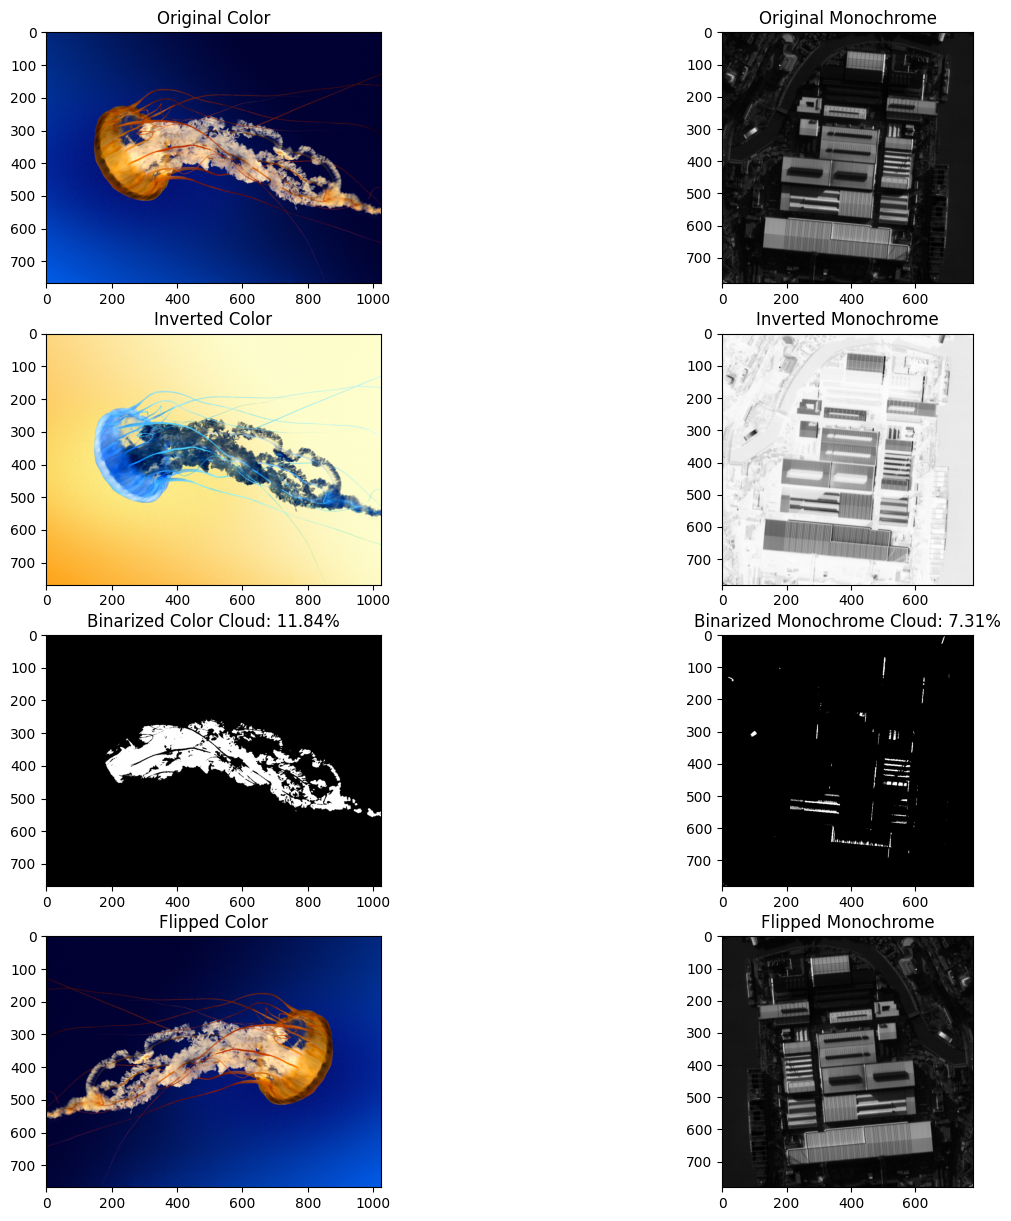


Записей в журнале: 437

Все события:
  ['ping', '2026-10-05 14:37:07']
  ['now', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['type', '2026-10-05 14:37:07']
  ['sum', '2026-10-05 14:37:07']
  ['pow', '2026-10-05 14:37:07']
  ['black_list_check', '2026-10-05 14:37:10']
  ['black_list_check', '2026-10-05 14:37:10']
  ['black_list_check', '2026-10-05 14:37:10']
  ['black_list_check', '2026-10-05 14:37:10']
  ['cloud_percent', '2026-10-05 14:37:12']
  ['cloud_percent', '2026-10-05 14:37:13']
  ['color_inversion', '2026-10-05 14:37:13']
  ['color_inversion', '2026-10-05 14:37:13']
  ['binarize_image', '2026-10-05 14:37:13']
  ['binarize_image', '2026-10-05 14:37:14']
  ['flip_vertical', '2026-10-05 14:37:14']
  ['flip_vertical', '2026-10-05 14:37:14']
  ['ping', '2026-10-05 14:37:15']
  ['sum', '2026-10-05 1

In [6]:
# Подготовка изображений 
img_color = Image.open('Jellyfish.jpg')
img_arr_color = np.array(img_color)
    
img_mono = Image.open('11.bmp')
img_arr_mono = np.array(img_mono)
    
#if img_arr_mono.ndim == 3:
#    img_arr_mono = img_arr_mono[:,:,0]

print("Изображения загружены.")
print(f"Color image shape: {img_arr_color.shape}, dtype: {img_arr_color.dtype}")
print(f"Mono image shape: {img_arr_mono.shape}, dtype: {img_arr_mono.dtype}")

# Сериализация изображений
pimg_color = xmlrpc.client.Binary(pickle.dumps(img_arr_color))
pimg_mono = xmlrpc.client.Binary(pickle.dumps(img_arr_mono))

# Пункт 2: Оценка процента облачности
print("Пункт 2: процент облачности")
threshold = 100
cloud_color = server.cloud_percent(pimg_color, threshold)
cloud_mono  = server.cloud_percent(pimg_mono, threshold)

print(f"Cloud percent (color): {cloud_color:.2f}%")
print(f"Cloud percent (mono):  {cloud_mono:.2f}%")

# Пункт 5: Инверсия
img_bin2_color = server.color_inversion(pimg_color)
img_arr_inv_color = pickle.loads(img_bin2_color.data)
    
img_bin2_mono = server.color_inversion(pimg_mono)
img_arr_inv_mono = pickle.loads(img_bin2_mono.data)
# Пункт 6: Бинаризация
threshold = 128
img_bin2_color_bw = server.binarize_image(pimg_color, threshold)
img_arr_bin_color = pickle.loads(img_bin2_color_bw.data)
    
img_bin2_mono_bw = server.binarize_image(pimg_mono, threshold)
img_arr_bin_mono = pickle.loads(img_bin2_mono_bw.data)
# Пункт 7: Разворот по вертикали 
img_bin2_color_flip = server.flip_vertical(pimg_color)
img_arr_flip_color = pickle.loads(img_bin2_color_flip.data)
    
img_bin2_mono_flip = server.flip_vertical(pimg_mono)
img_arr_flip_mono = pickle.loads(img_bin2_mono_flip.data)
# Отображение всех результатов
figure(figsize=(15, 15))

subplot(4, 2, 1)
imshow(img_arr_color)
title("Original Color")

subplot(4, 2, 2)
imshow(img_arr_mono, cmap='gray')
title("Original Monochrome")

subplot(4, 2, 3)
imshow(img_arr_inv_color)
title("Inverted Color")

subplot(4, 2, 4)
imshow(img_arr_inv_mono, cmap='gray')
title("Inverted Monochrome")

subplot(4, 2, 5)
imshow(img_arr_bin_color)
title(f"Binarized Color Cloud: {cloud_color:.2f}%")    

subplot(4, 2, 6)
imshow(img_arr_bin_mono, cmap='gray')
title(f"Binarized Monochrome Cloud: {cloud_mono:.2f}%") 

subplot(4, 2, 7)
imshow(img_arr_flip_color)
title("Flipped Color")

subplot(4, 2, 8)
imshow(img_arr_flip_mono, cmap='gray')
title("Flipped Monochrome")

show()

print("\nЗаписей в журнале:", len(stats.get_log()))
print("\nВсе события:")
for row in stats.get_log():
    print(" ", row)


In [7]:
print("Только ping")
for row in stats.get_log('ping'):
    print(" ", row)

print("Только cloud_percent")
for row in stats.get_log('cloud_percent'):
    print(" ", row)

print("Только black_list_check")
for row in stats.get_log('black_list_check'):
    print(" ", row)

dt_from = datetime.datetime(2026, 10, 5, 20,00,00,00).strftime("%Y-%m-%d %H:%M:%S")
dt_to   = datetime.datetime(2026, 10, 5, 20,50,00,00).strftime("%Y-%m-%d %H:%M:%S")

print(f"\nЗа последние 30 минут ({dt_from} .. {dt_to})")
for row in stats.get_log(None, dt_from, dt_to):    
    print(" ", row)

print("Комбинированный: за 30 минут")
for row in stats.get_log('flip_vertical', dt_from, dt_to):
    print(" ", row)

Только ping
  ['ping', '2026-10-05 14:37:07']
  ['ping', '2026-10-05 14:37:15']
  ['ping', '2026-10-05 14:51:45']
  ['ping', '2026-10-05 15:25:58']
  ['ping', '2026-10-05 16:02:32']
  ['ping', '2026-10-05 16:09:12']
  ['ping', '2026-10-05 16:11:32']
  ['ping', '2026-10-05 17:12:45']
  ['ping', '2026-10-05 17:14:49']
  ['ping', '2026-10-05 17:15:32']
  ['ping', '2026-10-05 18:32:36']
  ['ping', '2026-10-05 18:33:36']
  ['ping', '2026-10-05 18:34:57']
  ['ping', '2026-10-05 19:23:15']
  ['ping', '2026-10-05 20:45:31']
  ['ping', '2026-10-19 14:57:36']
Только cloud_percent
  ['cloud_percent', '2026-10-05 14:37:12']
  ['cloud_percent', '2026-10-05 14:37:13']
  ['cloud_percent', '2026-10-05 14:51:49']
  ['cloud_percent', '2026-10-05 14:51:49']
  ['cloud_percent', '2026-10-05 15:16:12']
  ['cloud_percent', '2026-10-05 15:16:12']
  ['cloud_percent', '2026-10-05 15:26:01']
  ['cloud_percent', '2026-10-05 15:26:02']
  ['cloud_percent', '2026-10-05 16:02:37']
  ['cloud_percent', '2026-10-05 16:0

In [41]:
# print(stats.system.listMethods())
# print(stats.ping_stats())

In [8]:
print("ping →", server.ping())
print("sum  →", server.sum(2, 3))
print("now  →", server.now())
print("Всё работает без stats")

ping → True
sum  → 5
now  → 20261005T19:24:18
Всё работает без stats
